# Ming generations: training, active life and the opportunities of each generation
Does the number of people a generation leaves in the database reflect the **opportunities** it had (to study, pass the exams, serve the state), rather than how many talented people it contained? If so, a thin generation in the data is a generation with few open doors, and many people who could have become known are missing.

Two sources, linked by the CBDB person id written in the Wikidata descriptions ("Ming dynasty person CBDB = 34486"):
- `cultura_enriched_v3.2`: birth year, active life and life-stage polities.
- CBDB (October 2026 SQLite): metropolitan exam degrees (**jinshi**) with their year, and office postings. The jinshi lists are the regime's supply of opportunities, exam by exam.

In [1]:
import tempfile

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'
CBDB_PATH = '../../data/similar_databases/cbdb/cbdb_20261024.sqlite3'

MING = 'Ming Dynasty'
TERRITORY_POLITIES = [MING, 'Later Jin Dynasty', 'Li Zicheng', 'Southern Ming', 'Qing Dynasty']
CULTURE_DOMAINS = ['Culture', 'Discovery/Science']
JINSHI = 'examination: jinshi (general)'
CBDB_ID_PATTERN = r'CBDB = (\d+)'

EXAM_START, EXAM_END = 1370, 1720
BIRTH_START, BIRTH_END = 1340, 1700
WELL_COVERED = (1400, 1590)
WANLI_START, WANLI_END = 1573, 1620
AGE_BINS = np.arange(10, 81, 2)

TYPE_ORDER = ['jinshi', 'other CBDB person', 'not in CBDB']
TYPE_COLORS = {'jinshi': BLUE, 'other CBDB person': LIGHT_BLUE, 'not in CBDB': ORANGE}
AGE_COLORS = {'jinshi degree (CBDB)': BLUE, 'first office (CBDB)': GREEN,
              'start of active life (Cultura)': ORANGE, 'end of active life (Cultura)': RED}
SUPPLY_COLOR = TEXT
WANLI_SHADE = {'color': PALE_BLUE, 'alpha': 0.6, 'lw': 0, 'zorder': 0}

apply_style()
pl.Config.set_tbl_rows(40)

polars.config.Config

## External data
CBDB, read in place from `data/similar_databases/cbdb` (downloaded from the CBDB Hugging Face repository). The Wanli reign (1573–1620) is the only constant not read from a database.

## Load data
### Cultura: individuals of the territory and individuals with a CBDB id
The territory is the one of notebook 08: Ming, Later Jin, Shun, Southern Ming and Qing, at any stage of life. Individuals with a CBDB id but no polity (no date, so no life stage) are kept too: they are the ones the territory misses.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")
con.sql(f"ATTACH '{CBDB_PATH}' AS cbdb (TYPE sqlite, READ_ONLY)")

ming_start, ming_end = con.sql("""
    SELECT min(territory.start_year), max(territory.end_year)
    FROM   polity, unnest(polity.territories) AS unnested(territory)
    WHERE  polity.name = $name
""", params={'name': MING}).fetchone()
print(f'Ming in Cliopatria: {ming_start}-{ming_end}')

cultura = con.sql("""
    WITH person AS (
        SELECT entity.qid                                                          AS qid,
               TRY_CAST(regexp_extract(entity.description, $pattern, 1) AS BIGINT) AS cbdb_id,
               birth_date.year                                                     AS birth_year,
               birth_date.source                                                   AS birth_source,
               start_of_active_life.year                                           AS active_start,
               end_of_active_life.year                                             AS active_end,
               start_of_active_life.source                                         AS active_source,
               list_has_any(list_transform(pre_active_life_polity || active_life_polity || post_active_life_polity,
                                           stage_match -> stage_match.polity.name), $names) AS in_territory,
               list_contains(list_transform(active_life_polity, stage_match -> stage_match.polity.name), $ming) AS active_in_ming
        FROM   individual_enriched
    )
    SELECT * FROM person WHERE in_territory OR cbdb_id IS NOT NULL
""", params={'pattern': CBDB_ID_PATTERN, 'names': TERRITORY_POLITIES, 'ming': MING}).pl()

culture_qids = con.sql("""
    SELECT DISTINCT person_occupation.qid
    FROM   (SELECT entity.qid AS qid, unnest(occupation).entity.qid AS occupation_qid FROM individual) AS person_occupation
    JOIN   occupation ON occupation.entity.qid = person_occupation.occupation_qid
    WHERE  list_contains($domains, occupation.meta_occupation)
""", params={'domains': CULTURE_DOMAINS}).pl()['qid']

cultura = cultura.with_columns(pl.col('qid').is_in(culture_qids.implode()).alias('is_culture'))
assert cultura['qid'].is_unique
print(f"individuals loaded: {cultura.height:,}")
print(f"  in the territory: {cultura['in_territory'].sum():,}")
print(f"  with a CBDB id: {cultura['cbdb_id'].is_not_null().sum():,} ({cultura['cbdb_id'].n_unique() - 1:,} distinct ids)")
cultura.sample(5, seed=42)

Ming in Cliopatria: 1375-1644


individuals loaded: 291,150
  in the territory: 52,442
  with a CBDB id: 276,186 (276,185 distinct ids)


qid,cbdb_id,birth_year,birth_source,active_start,active_end,active_source,in_territory,active_in_ming,is_culture
str,i64,i64,str,i64,i64,str,bool,bool,bool
"""Q45659150""",360480,null,null,null,null,null,false,false,false
"""Q45492066""",87534,1862,"""wikidata""",1903,1919,"""estimated""",true,false,false
"""Q19855880""",null,1431,"""wikidata""",1470,1489,"""estimated""",true,true,false
"""Q45620860""",110821,null,null,null,null,null,false,false,false
"""Q45652192""",292731,null,null,null,null,null,false,false,false


### CBDB: jinshi degrees, birth years and first office
One row per CBDB person with a jinshi degree (the earliest year when several are recorded), the birth year when known, and the first year of an office posting.

In [3]:
jinshi = con.sql("""
    WITH degree AS (
        SELECT ENTRY_DATA.c_personid AS cbdb_id, min(ENTRY_DATA.c_year) AS exam_year
        FROM   cbdb.ENTRY_DATA
        JOIN   cbdb.ENTRY_CODES ON ENTRY_CODES.c_entry_code = ENTRY_DATA.c_entry_code
        WHERE  ENTRY_CODES.c_entry_desc = $jinshi AND ENTRY_DATA.c_year > 0
        GROUP BY 1
    ),
    first_office AS (
        SELECT c_personid AS cbdb_id, min(c_firstyear) AS first_office_year
        FROM   cbdb.POSTED_TO_OFFICE_DATA
        WHERE  c_firstyear > 0
        GROUP BY 1
    )
    SELECT degree.cbdb_id,
           degree.exam_year,
           nullif(BIOG_MAIN.c_birthyear, 0)  AS cbdb_birth_year,
           first_office.first_office_year
    FROM   degree
    JOIN   cbdb.BIOG_MAIN ON BIOG_MAIN.c_personid = degree.cbdb_id
    LEFT JOIN first_office ON first_office.cbdb_id = degree.cbdb_id
""", params={'jinshi': JINSHI}).pl()

all_cbdb_ages = con.sql("""
    SELECT c_personid AS cbdb_id, nullif(c_birthyear, 0) AS cbdb_birth_year
    FROM   cbdb.BIOG_MAIN
    WHERE  c_birthyear > 0
""").pl()
first_office_all = con.sql("""
    SELECT c_personid AS cbdb_id, min(c_firstyear) AS first_office_year
    FROM   cbdb.POSTED_TO_OFFICE_DATA WHERE c_firstyear > 0 GROUP BY 1
""").pl()
con.close()

assert jinshi['cbdb_id'].is_unique
print(f"CBDB jinshi with a year: {jinshi.height:,}")
print(f"  {EXAM_START}-{EXAM_END - 1}: {jinshi.filter(pl.col('exam_year').is_between(EXAM_START, EXAM_END - 1)).height:,}")
print(f"  with a birth year: {jinshi['cbdb_birth_year'].is_not_null().sum():,}")
jinshi.sample(5, seed=42)

CBDB jinshi with a year: 82,754
  1370-1719: 32,754
  with a birth year: 17,664


cbdb_id,exam_year,cbdb_birth_year,first_office_year
i64,i64,i64,i64
537290,1109,null,null
548697,1145,null,null
544561,1244,null,null
533659,1265,null,null
347763,1640,null,null


## Preprocessing
### 1. The life course: training, exam, office and active life
Ages from CBDB for the Ming-era jinshi (exam 1370–1644): age at the degree and at the first office (birth year from CBDB). For Cultura, the age at the start and end of the active life of individuals whose active life is in the Ming.

In [4]:
ming_jinshi = jinshi.filter(pl.col('exam_year').is_between(EXAM_START, ming_end), pl.col('cbdb_birth_year').is_not_null())
first_office_ages = (
    first_office_all.join(all_cbdb_ages, on='cbdb_id')
    .filter(pl.col('first_office_year').is_between(EXAM_START, ming_end))
    .select((pl.col('first_office_year') - pl.col('cbdb_birth_year')).alias('age'))
)
ming_cultura = cultura.filter(pl.col('active_in_ming'), pl.col('birth_year').is_not_null())

ages = {
    'jinshi degree (CBDB)': ming_jinshi.select((pl.col('exam_year') - pl.col('cbdb_birth_year')).alias('age'))['age'],
    'first office (CBDB)': first_office_ages['age'],
    'start of active life (Cultura)': (ming_cultura['active_start'] - ming_cultura['birth_year']),
    'end of active life (Cultura)': (ming_cultura['active_end'] - ming_cultura['birth_year']),
}
ages = {name: series.filter(series.is_between(AGE_BINS[0], AGE_BINS[-1])) for name, series in ages.items()}

life_course = pl.DataFrame({
    'step': list(ages),
    'individuals': [series.len() for series in ages.values()],
    'p10': [series.quantile(0.1) for series in ages.values()],
    'median': [series.median() for series in ages.values()],
    'p90': [series.quantile(0.9) for series in ages.values()],
})
print('Cultura Ming active lives by source:', dict(ming_cultura['active_source'].value_counts().iter_rows()))
life_course

Cultura Ming active lives by source: {'dated works and positions': 67, 'estimated': 16381}


step,individuals,p10,median,p90
str,i64,f64,f64,f64
"""jinshi degree (CBDB)""",12178,25.0,32.0,39.0
"""first office (CBDB)""",957,22.0,33.0,50.0
"""start of active life (Cultura)""",16419,36.0,39.0,41.0
"""end of active life (Cultura)""",16425,54.0,58.0,58.0


### 2. Supply of opportunities: jinshi degrees per exam
Every CBDB exam year with at least one jinshi. The metropolitan exam was held every three years, so each bar is one exam.

In [5]:
exams = (
    jinshi.filter(pl.col('exam_year').is_between(EXAM_START, EXAM_END - 1))
    .group_by('exam_year').len('jinshi').sort('exam_year')
)
print(f"exam years: {exams.height}, median jinshi per exam year: {exams['jinshi'].median():.0f}")
print(f"Ming ({ming_start}-{ming_end}): {exams.filter(pl.col('exam_year') <= ming_end)['jinshi'].sum():,} jinshi")
exams.filter(pl.col('exam_year').is_between(WANLI_START - 10, WANLI_END + 10))

exam years: 189, median jinshi per exam year: 163
Ming (1375-1644): 25,631 jinshi


exam_year,jinshi
i64,u32
1564,1
1565,411
1567,1
1568,436
1571,408
1572,2
1573,1
1574,325
1576,2


### 3. How much of each exam the database holds
For every exam decade: the CBDB jinshi, those in Cultura (CBDB id in a description), and those counted in the territory (they need a birth or death year to get a life-stage polity).

In [6]:
cultura_cbdb = cultura.filter(pl.col('cbdb_id').is_not_null()).unique('cbdb_id', keep='first')
linked = jinshi.join(cultura_cbdb.select('cbdb_id', 'qid', 'in_territory', 'birth_year', 'is_culture'), on='cbdb_id', how='left')
assert linked.height == jinshi.height

coverage = (
    linked.filter(pl.col('exam_year').is_between(EXAM_START, EXAM_END - 1))
    .group_by((pl.col('exam_year') // 10 * 10).alias('exam_decade'))
    .agg(pl.len().alias('cbdb_jinshi'),
         pl.col('qid').is_not_null().sum().alias('in_cultura'),
         pl.col('in_territory').fill_null(False).sum().alias('in_territory'))
    .sort('exam_decade')
    .with_columns((pl.col('in_cultura') / pl.col('cbdb_jinshi') * 100).round(1).alias('in_cultura_%'),
                  (pl.col('in_territory') / pl.col('in_cultura') * 100).round(1).alias('dated_among_cultura_%'))
)
print(f"jinshi {EXAM_START}-{EXAM_END - 1} in Cultura: {coverage['in_cultura'].sum():,}, dated: {coverage['in_territory'].sum():,}, undated: {(coverage['in_cultura'] - coverage['in_territory']).sum():,}")
for start, end in [(1480, 1590), (1600, 1650)]:
    period = coverage.filter(pl.col('exam_decade').is_between(start, end - 1))
    print(f"  exams {start}-{end - 1}: {period['in_cultura'].sum() / period['cbdb_jinshi'].sum():.0%} in Cultura, {period['in_territory'].sum() / period['in_cultura'].sum():.0%} of them dated")
coverage

jinshi 1370-1719 in Cultura: 20,901, dated: 8,917, undated: 11,984
  exams 1480-1589: 74% in Cultura, 72% of them dated
  exams 1600-1649: 59% in Cultura, 9% of them dated


exam_decade,cbdb_jinshi,in_cultura,in_territory,in_cultura_%,dated_among_cultura_%
i64,u32,u32,u32,f64,f64
1370,133,80,9,60.2,11.2
1380,527,334,8,63.4,2.4
1390,248,118,3,47.6,2.5
1400,830,435,74,52.4,17.0
1410,812,468,27,57.6,5.8
1420,469,267,11,56.9,4.1
1430,419,107,46,25.5,43.0
1440,473,133,103,28.1,77.4
1450,886,288,233,32.5,80.9


### 4. Generations: what each birth cohort obtained, and what the database keeps of it
A jinshi belongs to the generation of their birth decade: the CBDB birth year, else the exam year minus the median age at the degree. Cultura individuals of the territory are counted by birth decade and split into jinshi, other CBDB persons, and individuals not in CBDB.

In [7]:
median_exam_age = int(life_course.filter(pl.col('step') == 'jinshi degree (CBDB)')['median'][0])
supply = (
    jinshi.with_columns(pl.coalesce('cbdb_birth_year', pl.col('exam_year') - median_exam_age).alias('generation_birth'))
    .filter(pl.col('generation_birth').is_between(BIRTH_START, BIRTH_END - 1))
    .group_by((pl.col('generation_birth') // 10 * 10).alias('decade')).len('jinshi_of_generation')
)

jinshi_ids = jinshi['cbdb_id'].implode()
territory_born = (
    cultura.filter(pl.col('in_territory'), pl.col('birth_year').is_between(BIRTH_START, BIRTH_END - 1))
    .with_columns(
        (pl.col('birth_year') // 10 * 10).alias('decade'),
        pl.when(pl.col('cbdb_id').is_in(jinshi_ids)).then(pl.lit('jinshi'))
        .when(pl.col('cbdb_id').is_not_null()).then(pl.lit('other CBDB person'))
        .otherwise(pl.lit('not in CBDB')).alias('type'),
    )
)
generations = (
    pl.DataFrame({'decade': range(BIRTH_START, BIRTH_END, 10)})
    .join(territory_born.group_by('decade', 'type').len().pivot(on='type', index='decade', values='len'), on='decade', how='left')
    .join(territory_born.filter('is_culture').group_by('decade').len('culture_science'), on='decade', how='left')
    .join(supply, on='decade', how='left')
    .fill_null(0)
    .select('decade', *TYPE_ORDER, 'culture_science', 'jinshi_of_generation')
    .with_columns(pl.sum_horizontal(TYPE_ORDER).alias('cultura_born'))
)
assert generations['cultura_born'].sum() == territory_born.height
print(f'median age at the jinshi: {median_exam_age}')
for start, end in [(1450, 1570), (1580, 1640)]:
    period = generations.filter(pl.col('decade').is_between(start, end - 1))
    print(f"born {start}-{end - 1}: {period['cultura_born'].sum():,} individuals, jinshi {period['jinshi'].sum() / period['cultura_born'].sum():.0%}, "
          f"other CBDB {period['other CBDB person'].sum() / period['cultura_born'].sum():.0%}, not in CBDB {period['not in CBDB'].sum() / period['cultura_born'].sum():.0%}")
generations

median age at the jinshi: 32
born 1450-1569: 9,875 individuals, jinshi 70%, other CBDB 8%, not in CBDB 23%
born 1580-1639: 5,532 individuals, jinshi 8%, other CBDB 68%, not in CBDB 24%


decade,jinshi,other CBDB person,not in CBDB,culture_science,jinshi_of_generation,cultura_born
i64,u32,u32,u32,u32,u32,u32
1340,9,82,32,11,8,123
1350,3,71,35,21,554,109
1360,20,85,61,30,282,166
1370,55,89,134,39,877,278
1380,21,65,134,15,900,220
1390,41,86,131,24,388,258
1400,50,57,247,17,370,354
1410,106,64,335,12,533,505
1420,218,45,608,24,859,871


### 5. Does the size of a generation in Cultura follow its opportunities?
Correlation across birth decades between the jinshi a generation obtained and the individuals Cultura keeps of it, on the decades where the database holds most of the exams (born 1400–1589).

In [8]:
window = generations.filter(pl.col('decade').is_between(WELL_COVERED[0], WELL_COVERED[1] - 1))
correlations = pl.DataFrame({
    'cultura group': ['all born in the territory', 'jinshi', 'other CBDB person', 'not in CBDB', 'culture and science'],
    'pearson_r': [np.corrcoef(window['jinshi_of_generation'], window[column])[0, 1].round(2)
                  for column in ['cultura_born', 'jinshi', 'other CBDB person', 'not in CBDB', 'culture_science']],
})
print(f'{window.height} birth decades')
correlations

19 birth decades


cultura group,pearson_r
str,f64
"""all born in the territory""",0.55
"""jinshi""",0.58
"""other CBDB person""",0.1
"""not in CBDB""",-0.19
"""culture and science""",0.57


## Figures
### Figure 1: The life course of a Ming scholar-official
Ages at the jinshi degree and at the first office (CBDB, Ming exams), and at the start and end of the active life in Cultura (Ming active lives). Shaded: training, before the median age at the degree.

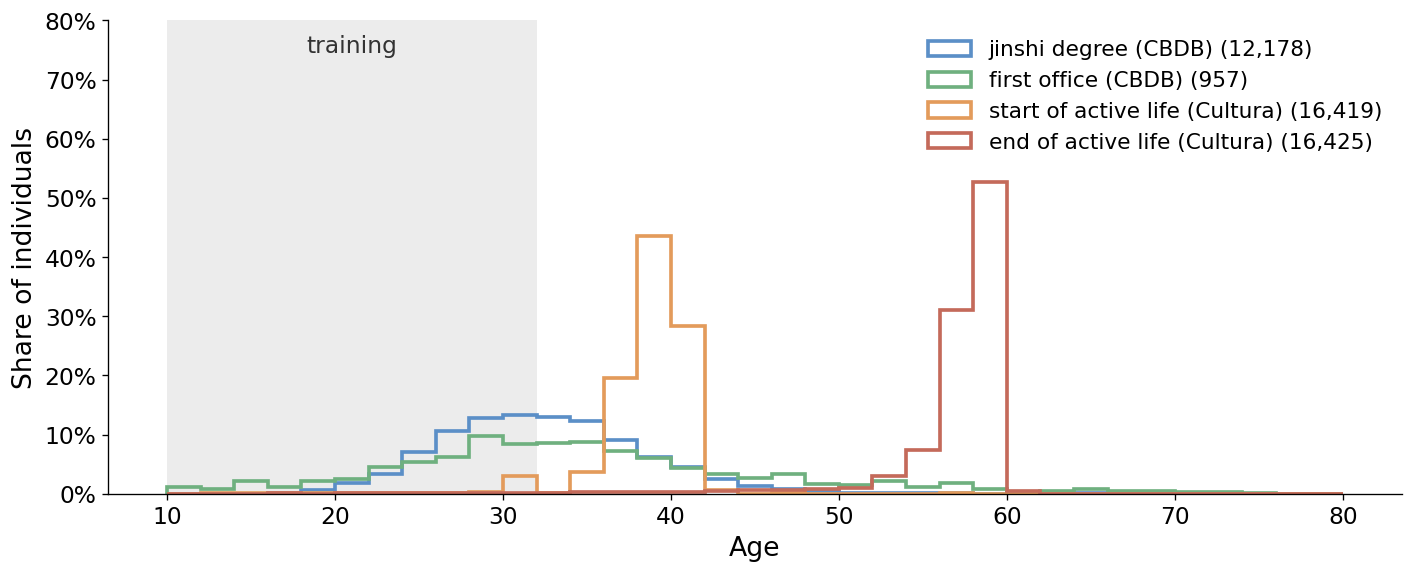

In [9]:
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.axvspan(AGE_BINS[0], median_exam_age, color=PALE_GREY, lw=0, zorder=0)
ax.text((AGE_BINS[0] + median_exam_age) / 2, 0.97, 'training', transform=ax.get_xaxis_transform(), ha='center', va='top', color=TEXT)
for name, series in ages.items():
    weights = np.full(series.len(), 100 / series.len())
    ax.hist(series, bins=AGE_BINS, weights=weights, histtype='step', lw=2.2, color=AGE_COLORS[name], label=f'{name} ({series.len():,})')
ax.set_xlabel('Age')
ax.set_ylabel('Share of individuals')
ax.yaxis.set_major_formatter(PERCENT)
ax.set_ylim(0, 80)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

### Figure 2: Jinshi degrees per exam, 1370–1720
CBDB. Shaded: Wanli era. Dotted line: end of the Ming in Cliopatria.

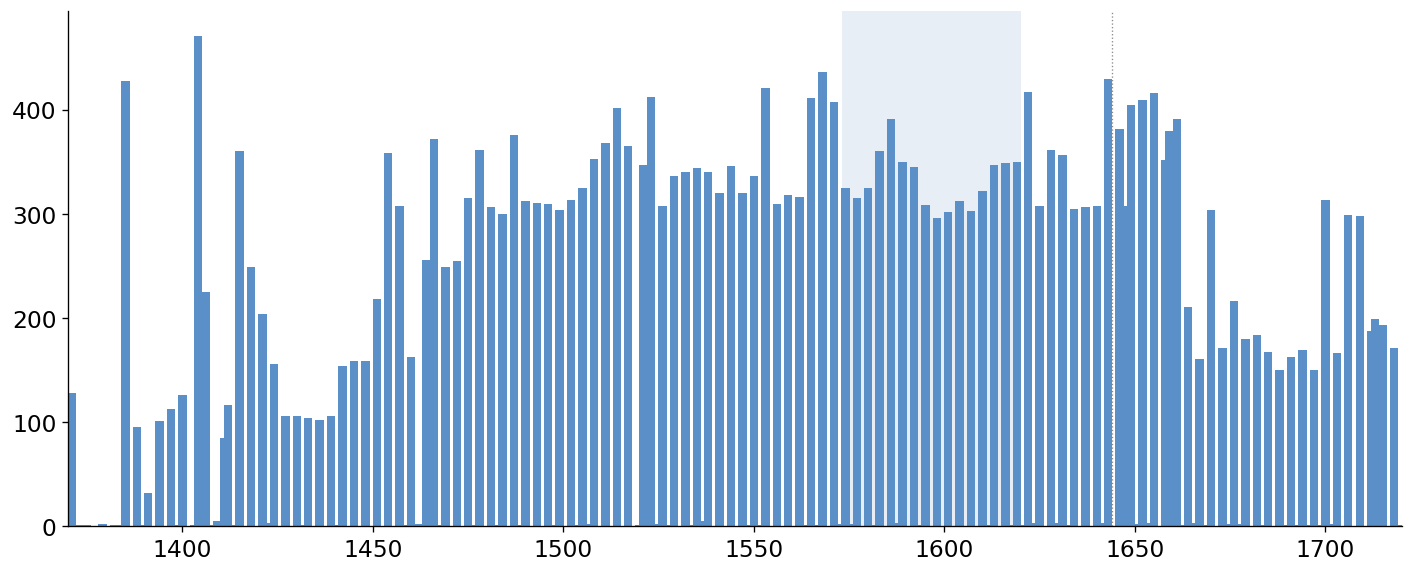

In [10]:
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.axvspan(WANLI_START, WANLI_END, **WANLI_SHADE)
ax.bar(exams['exam_year'], exams['jinshi'], width=2.2, color=BLUE)
ax.axvline(ming_end, **REFERENCE_LINE)
ax.set_xlim(EXAM_START, EXAM_END)
ax.yaxis.set_major_formatter(THOUSANDS)
plt.tight_layout()
plt.show()

### Figure 3: How much of each exam decade is in Cultura, and how much is dated
Grey: all CBDB jinshi. Light blue: in Cultura. Blue: in Cultura with a date, so in the territory and in every count by year.

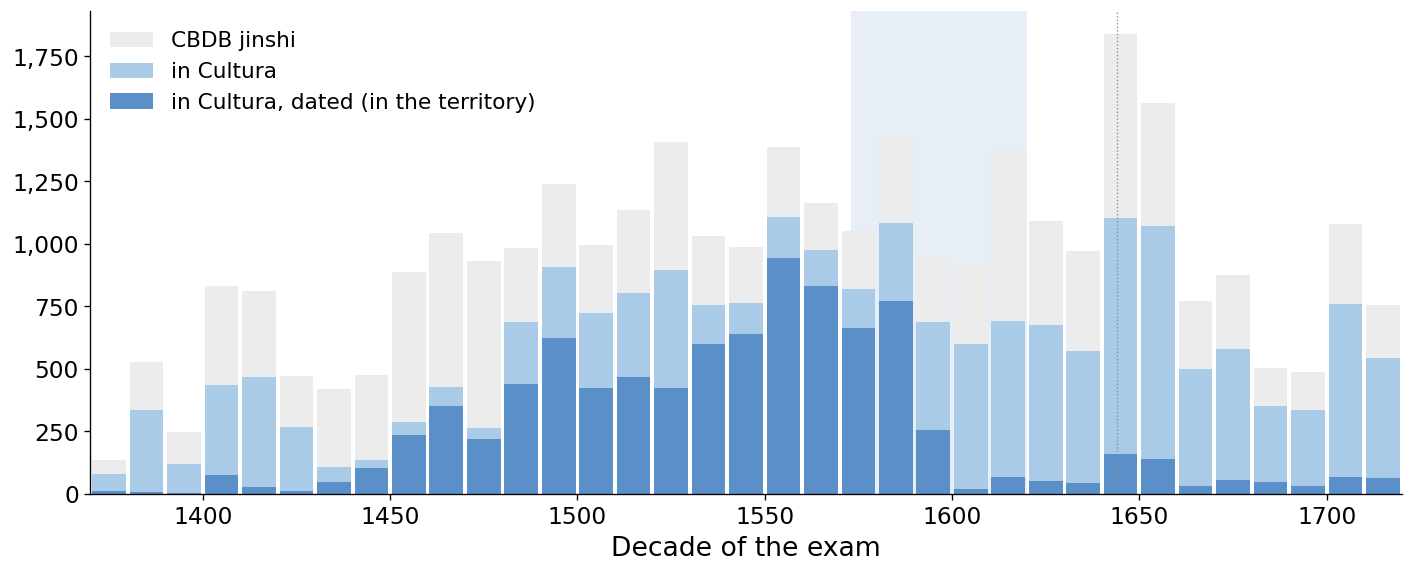

In [11]:
fig, ax = plt.subplots(figsize=FIGSIZE)
x = coverage['exam_decade'] + 5
ax.bar(x, coverage['cbdb_jinshi'], width=9, color=PALE_GREY, label='CBDB jinshi')
ax.bar(x, coverage['in_cultura'], width=9, color=LIGHT_BLUE, label='in Cultura')
ax.bar(x, coverage['in_territory'], width=9, color=BLUE, label='in Cultura, dated (in the territory)')
ax.axvspan(WANLI_START, WANLI_END, **WANLI_SHADE)
ax.axvline(ming_end, **REFERENCE_LINE)
ax.set_xlim(EXAM_START, EXAM_END)
ax.set_xlabel('Decade of the exam')
ax.yaxis.set_major_formatter(THOUSANDS)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

### Figure 4: Each generation in Cultura and the jinshi it obtained
Bars: individuals of the territory by decade of birth. Line: jinshi obtained by the generation born that decade (CBDB, all of them, in Cultura or not).

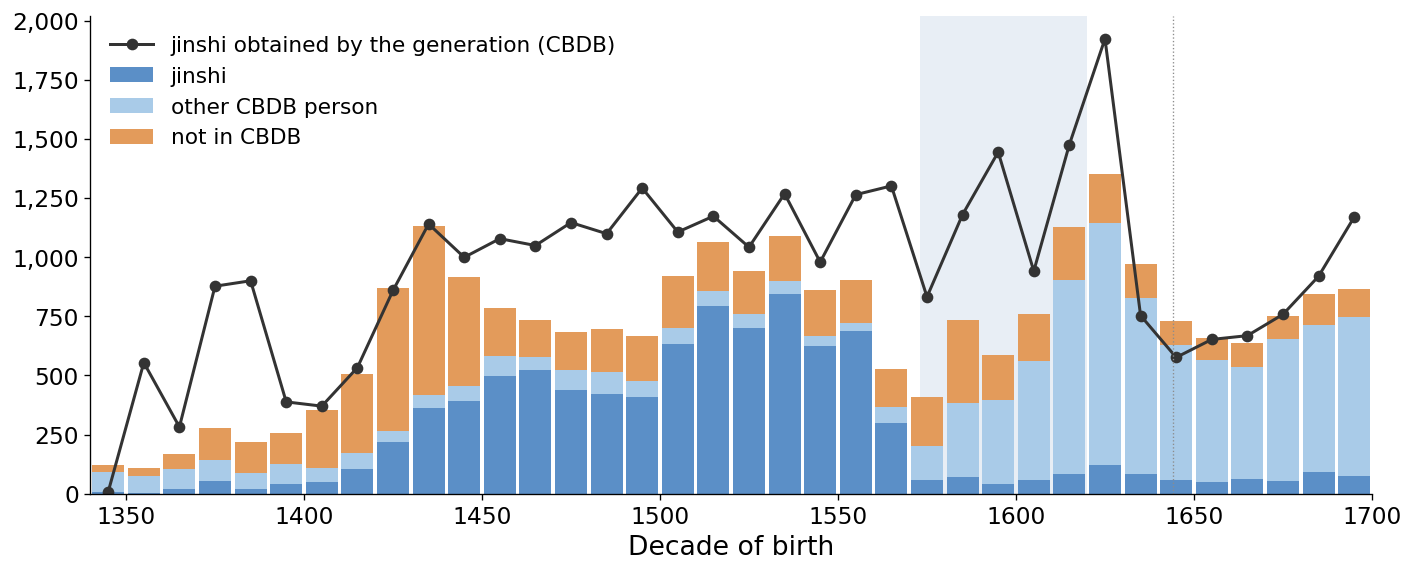

In [12]:
fig, ax = plt.subplots(figsize=FIGSIZE)
x = generations['decade'] + 5
bottom = np.zeros(generations.height)
for name in TYPE_ORDER:
    ax.bar(x, generations[name], width=9, bottom=bottom, color=TYPE_COLORS[name], label=name)
    bottom += generations[name].to_numpy()
ax.plot(x, generations['jinshi_of_generation'], color=SUPPLY_COLOR, marker='o', lw=1.8, label='jinshi obtained by the generation (CBDB)')
ax.axvspan(WANLI_START, WANLI_END, **WANLI_SHADE)
ax.axvline(ming_end, **REFERENCE_LINE)
ax.set_xlim(BIRTH_START, BIRTH_END)
ax.set_xlabel('Decade of birth')
ax.yaxis.set_major_formatter(THOUSANDS)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

### Figure 5: Opportunities and visibility, generation by generation (born 1400–1589)
Each point is a birth decade. Left: all individuals of the territory. Right: cultural producers and scientists.

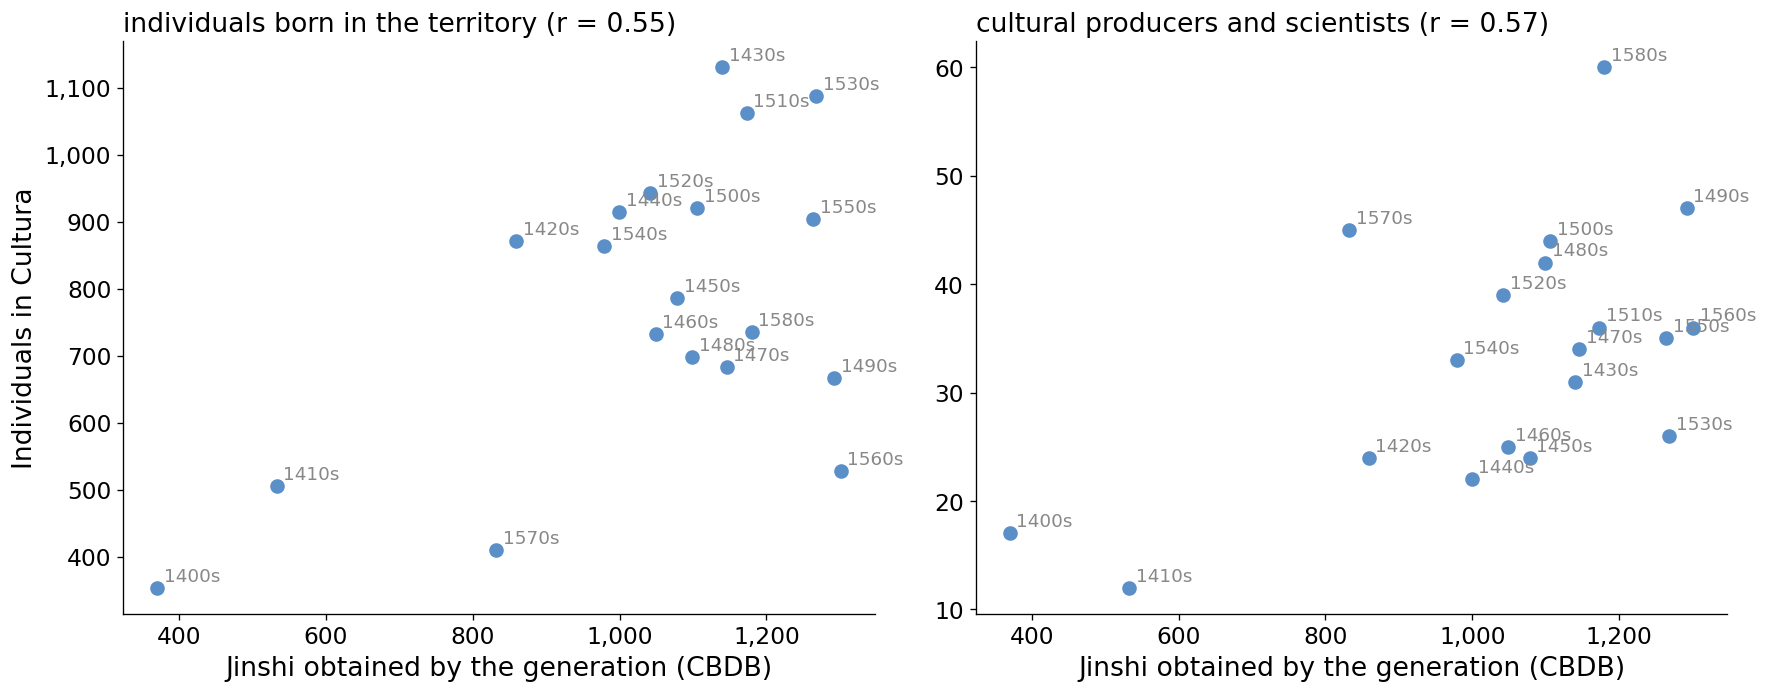

In [13]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_WIDE)
for ax, column, label in [(axes[0], 'cultura_born', 'individuals born in the territory'), (axes[1], 'culture_science', 'cultural producers and scientists')]:
    ax.scatter(window['jinshi_of_generation'], window[column], s=60, color=BLUE)
    for row in window.iter_rows(named=True):
        ax.annotate(f"{row['decade']}s", (row['jinshi_of_generation'], row[column]), xytext=(4, 4), textcoords='offset points', fontsize=POINT_LABEL_FONTSIZE, color=MUTED_TEXT)
    r = np.corrcoef(window['jinshi_of_generation'], window[column])[0, 1]
    ax.set_title(f'{label} (r = {r:.2f})', loc='left')
    ax.set_xlabel('Jinshi obtained by the generation (CBDB)')
    ax.xaxis.set_major_formatter(THOUSANDS)
    ax.yaxis.set_major_formatter(THOUSANDS)
axes[0].set_ylabel('Individuals in Cultura')
plt.tight_layout()
plt.show()

## What the data shows
**How a Ming life is laid out (Figure 1).** Training runs until the jinshi degree: median age 32, 80% between 25 and 39 (CBDB, 12,178 Ming graduates with a birth year). First office comes at about the same age (median 33). In Cultura, 99.6% of Ming active lives (16,381 of 16,448) are *estimated*: birth year plus a cohort age, so they start at 36-41 and end at 54-58. The active life therefore begins about seven years after the degree and covers the official career. But a count of people active per year is only the births shifted by about 40 years. It cannot measure opportunities on its own.

**The supply of opportunities (Figure 2).** About 25,600 Ming jinshi in CBDB, about 300-440 per regular exam in the Wanli era. That is roughly 1,000 per decade from 1450 onwards, with swings that partly come from having three or four exams in a decade. The quotas stayed nearly flat while the population of China grew strongly over the dynasty (a historiographical point, not measured here), so each generation's chance of a degree fell.

**The Ming part of the database is the exam register (Figures 3 and 4).** Of the territory individuals born 1450-1569, 70% are jinshi graduates in CBDB. Cultura holds 74% of all jinshi of the exams 1480-1589. In that period a person is in the database mostly *because* they passed the exam. Your idea holds there almost by construction: the data record who got through the door, not how many talented people were born.

**Does a generation's size follow its opportunities? (Figure 5)** Partly. Across the birth decades 1400-1589, the people Cultura keeps correlate with the jinshi their generation obtained (r = 0.55). The thin generations (1400s, 1410s, 1570s) are the ones with few degrees. Cultural producers and scientists follow the degrees as well (r = 0.57). So there is no sign that scarce degrees pushed more scholars into the arts. The people who are not in CBDB do not follow the degrees (r = -0.19). Their largest block is about 1,600 Ming items born in the 1420s-1430s and described only as "politician", one Wikidata import.

**A low count is not always few opportunities.** After 1590 the exams are as large as before, and Cultura still holds 59% of the jinshi of 1600-1649. But only 9% of those have a date, against 72% before (11,984 undated jinshi in all). CBDB itself rarely gives their birth year, only an index year. Without dates they get no life stage and no polity, so they leave the cohort counts. The generations born 1580-1639 are therefore made of other CBDB persons (68%: literati from Qing collections) instead of jinshi (8%). Before and after 1570 the database applies two different filters: the exam lists, then the literary record of the Ming-Qing transition. Comparing generations across that line compares the filters, not the opportunities. The post-Wanli fall in notebook 08 and the peak of the 1615-1629 cohorts in notebook 09 come mostly from this.

**Next step.** The jinshi year is a precise trace of the moment of opportunity. Giving the 11,984 undated jinshi an active life from their exam year would restore the late Ming in every count, and would make the opportunity test possible for 1590-1700.